<a href="https://colab.research.google.com/github/fathimanoorjahan03-afk/Intermediate_assessment_3/blob/main/intermediate_assessment_3_FathimaN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train_path = "/content/drive/MyDrive/DSA/kaggle competition/train.csv"

test_path = "/content/drive/MyDrive/DSA/kaggle competition/test.csv"

submission_path = "/content/drive/MyDrive/DSA/kaggle competition/sample_submission.csv"

In [ ]:
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample_submission = pd.read_csv(submission_path)

print("Training shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

display(train.head())
display(test.head())
display(sample_submission.head())

Training shape: (94, 14)
Test shape: (41, 13)
Sample submission shape: (3, 2)


,id,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,0J4_2016,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,A68_2016,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,E55_2015,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,7C7_2016,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,2C0_2018,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73


,id,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,A70_2018,183.57,117.18,87.90,53.60,33.10,26.50,95.70,52.5,98.6,104.4,208.8,3.35
1,5C9_2018,166.60,105.05,80.63,51.64,31.31,26.10,88.82,50.7,93.4,101.4,202.8,2.43
2,5E1_2018,175.53,111.23,84.93,53.74,32.75,24.93,91.42,51.3,94.2,103.4,206.8,2.99
3,C58_2018,187.85,116.90,87.52,54.22,35.10,27.00,99.48,52.3,99.8,107.6,215.2,3.55
4,5E2_2018,182.67,116.40,87.24,54.57,33.59,25.40,96.43,53.4,100.3,110.1,220.2,3.06


,id,sexo
0,id_1,M
1,id_2,H
2,id_3,M


In [ ]:
print("Training dataset columns:")
print(train.columns.tolist())

print("\nTest dataset columns:")
print(test.columns.tolist())

Training dataset columns:
['id', 'sexo', 'longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']

Test dataset columns:
['id', 'longitudCraneo', 'longitudPico', 'longitudNarina', 'anchoCraneo', 'altoPico', 'anchoPico', 'tarso', 'longAlaCerrada', 'longAlaAbierta', 'mediaEnvergadura', 'envergadura', 'peso']


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                94 non-null     object 
 1   sexo              94 non-null     object 
 2   longitudCraneo    94 non-null     float64
 3   longitudPico      94 non-null     float64
 4   longitudNarina    94 non-null     float64
 5   anchoCraneo       94 non-null     float64
 6   altoPico          94 non-null     float64
 7   anchoPico         94 non-null     float64
 8   tarso             94 non-null     float64
 9   longAlaCerrada    94 non-null     float64
 10  longAlaAbierta    94 non-null     float64
 11  mediaEnvergadura  94 non-null     float64
 12  envergadura       94 non-null     float64
 13  peso              93 non-null     float64
dtypes: float64(12), object(2)
memory usage: 10.4+ KB


In [ ]:
train.describe()

,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
count,94.000000,94.000000,94.000000,94.000000,94.000000,94.000000,94.00000,94.000000,94.000000,94.000000,94.000000,93.000000
mean,176.580106,110.130426,82.936383,52.687553,32.535000,25.425319,90.88766,51.667021,96.259043,104.765213,209.530426,2.624516
std,5.443278,4.028920,3.187515,2.226749,1.383418,1.439065,2.85098,1.185340,2.187660,2.486498,4.972997,0.315968
min,165.580000,102.710000,74.820000,46.500000,29.340000,21.480000,84.04000,48.700000,88.900000,99.300000,198.600000,2.030000
25%,172.187500,106.835000,80.217500,51.207500,31.605000,24.500000,88.66000,51.000000,94.725000,103.175000,206.350000,2.400000
50%,176.915000,110.070000,83.325000,52.475000,32.605000,25.480000,91.03500,51.600000,96.500000,104.950000,209.900000,2.600000
75%,180.525000,113.252500,85.425000,54.347500,33.460000,26.372500,92.57000,52.475000,97.875000,106.550000,213.100000,2.830000
max,191.210000,119.480000,90.680000,58.360000,35.500000,28.700000,99.69000,54.700000,101.300000,112.200000,224.400000,3.530000


In [ ]:
print("Missing values in training data:")
print(train.isnull().sum())

print("\nMissing values in test data:")
print(test.isnull().sum())

Missing values in training data:
id                  0
sexo                0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                1
dtype: int64

Missing values in test data:
id                  0
longitudCraneo      0
longitudPico        0
longitudNarina      0
anchoCraneo         0
altoPico            0
anchoPico           0
tarso               0
longAlaCerrada      0
longAlaAbierta      0
mediaEnvergadura    0
envergadura         0
peso                0
dtype: int64


In [ ]:
train.drop(columns=['id'],inplace=True)
train

,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,envergadura,peso
0,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,208.4,2.38
1,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,204.4,2.14
2,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,210.4,2.50
3,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,215.2,2.83
4,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,207.4,2.73
...,...,...,...,...,...,...,...,...,...,...,...,...,...
89,H,168.18,106.70,80.30,49.20,31.30,24.50,91.30,53.4,98.6,105.9,211.8,2.73
90,H,173.95,106.88,81.77,50.27,32.54,25.65,88.64,52.4,96.0,105.9,211.8,2.65
91,M,181.01,109.98,82.95,55.47,32.84,25.84,90.78,51.4,96.0,105.4,210.8,2.55
92,M,181.51,112.57,85.58,54.11,32.60,26.02,93.11,53.0,98.0,107.4,214.8,3.10


In [ ]:
# Select numerical columns, excluding the target
numeric_cols = train.select_dtypes(include=np.number).columns

# Calculate outlier counts using IQR
outlier_counts = {}

for col in numeric_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train[
        (train[col] < lower_bound) |
        (train[col] > upper_bound)
    ]

    outlier_counts[col] = len(outliers)

# Display outlier counts
outlier_summary = pd.DataFrame(
    outlier_counts.items(),
    columns=['Feature', 'Outlier Count']
)

print(outlier_summary)

             Feature  Outlier Count
0     longitudCraneo              0
1       longitudPico              0
2     longitudNarina              0
3        anchoCraneo              0
4           altoPico              0
5          anchoPico              2
6              tarso              2
7     longAlaCerrada              2
8     longAlaAbierta              1
9   mediaEnvergadura              1
10       envergadura              1
11              peso              2


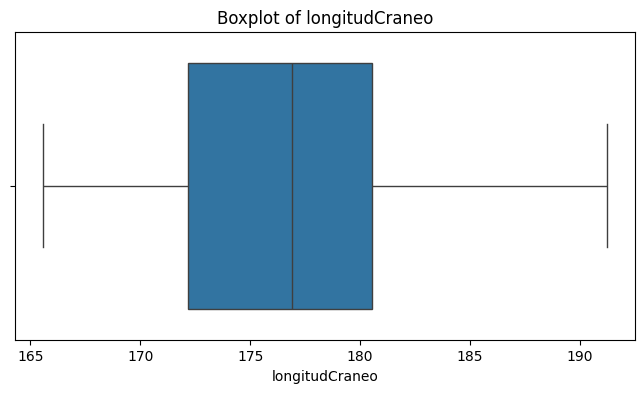

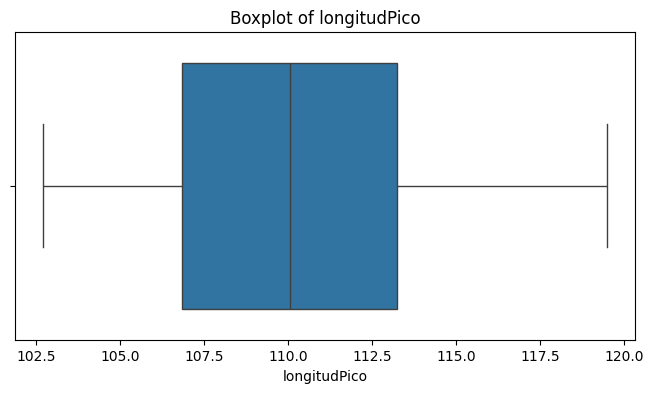

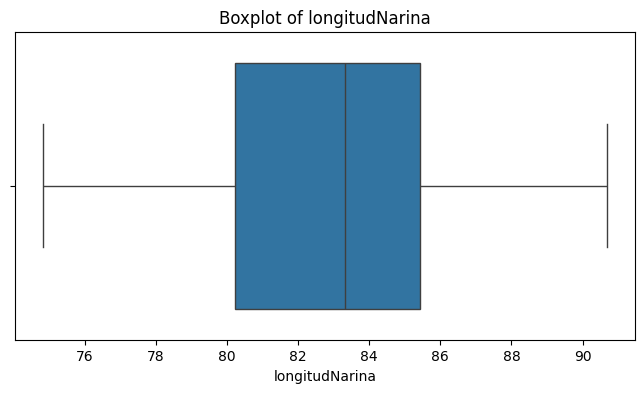

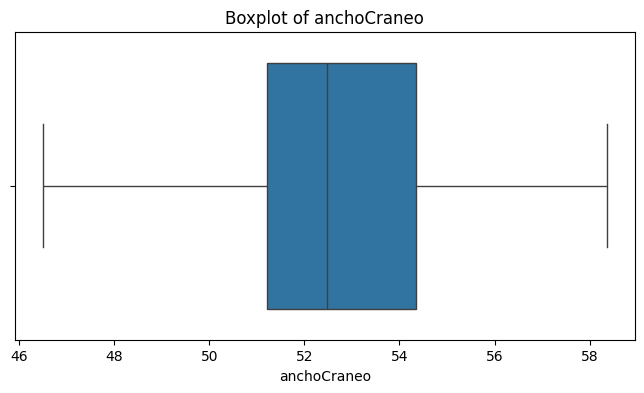

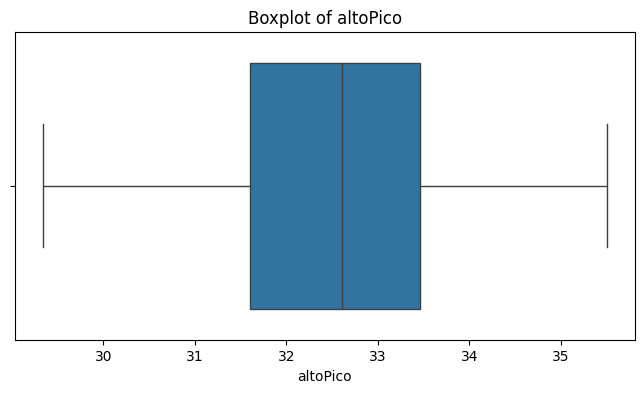

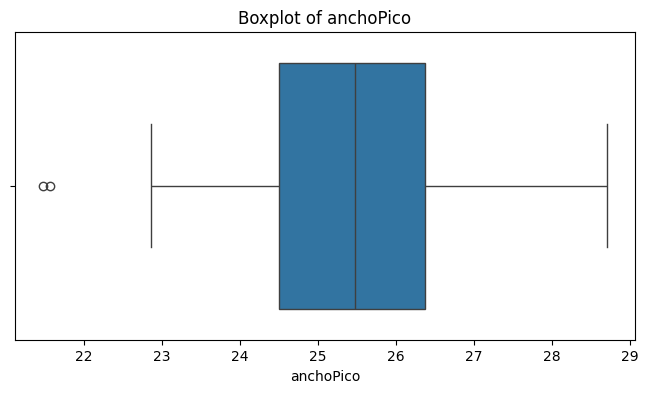

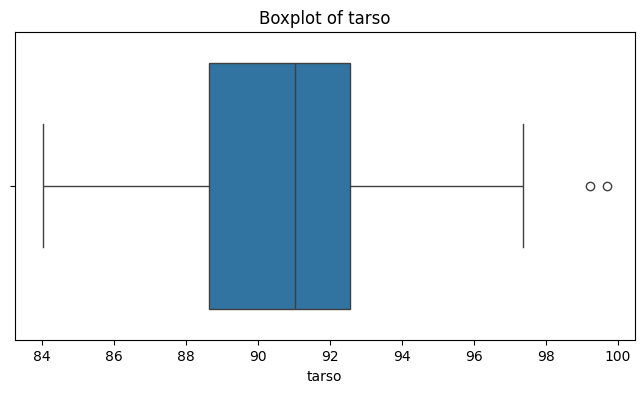

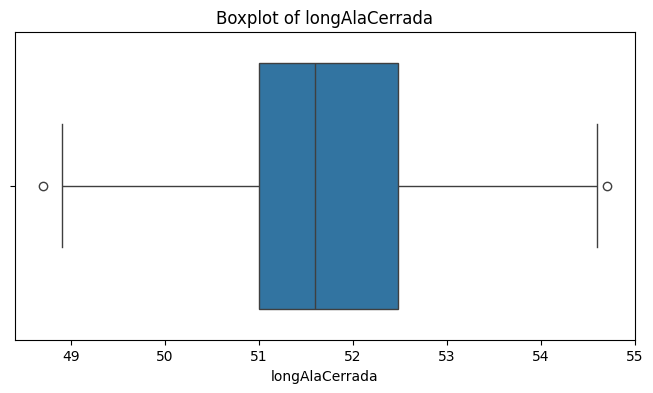

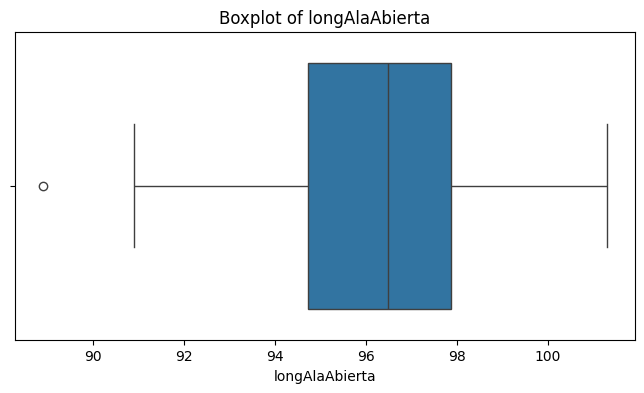

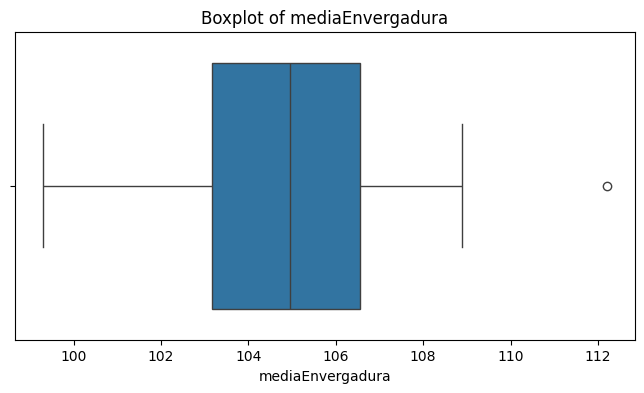

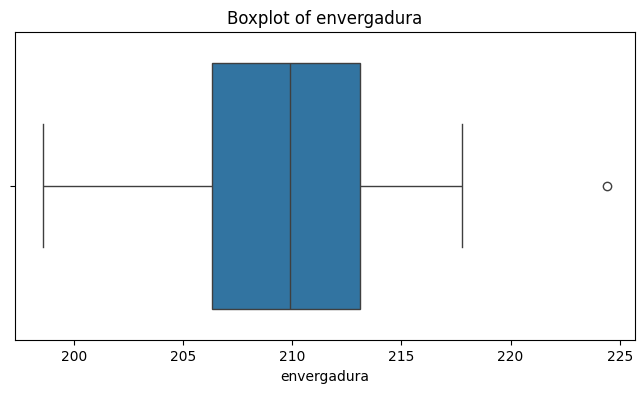

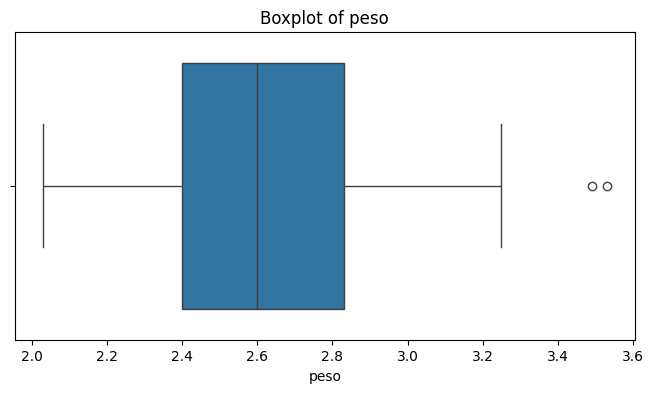

In [ ]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=train[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [ ]:
numeric_cols = train.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = train[col].quantile(0.25)
    Q3 = train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = train.loc[
        (train[col] < lower) | (train[col] > upper),
        [col, 'sexo']
    ]

    if not outliers.empty:
        print(f"\n{col}:")
        print(outliers)
        print(f"Acceptable IQR range: {lower:.2f} to {upper:.2f}")


anchoPico:
    anchoPico sexo
38      21.57    H
44      21.48    H
Acceptable IQR range: 21.69 to 29.18

tarso:
    tarso sexo
25  99.23    H
45  99.69    M
Acceptable IQR range: 82.80 to 98.43

longAlaCerrada:
    longAlaCerrada sexo
13            54.7    H
53            48.7    H
Acceptable IQR range: 48.79 to 54.69

longAlaAbierta:
    longAlaAbierta sexo
82            88.9    H
Acceptable IQR range: 90.00 to 102.60

mediaEnvergadura:
    mediaEnvergadura sexo
32             112.2    M
Acceptable IQR range: 98.11 to 111.61

envergadura:
    envergadura sexo
32        224.4    M
Acceptable IQR range: 196.22 to 223.22

peso:
    peso sexo
28  3.49    M
67  3.53    M
Acceptable IQR range: 1.75 to 3.48


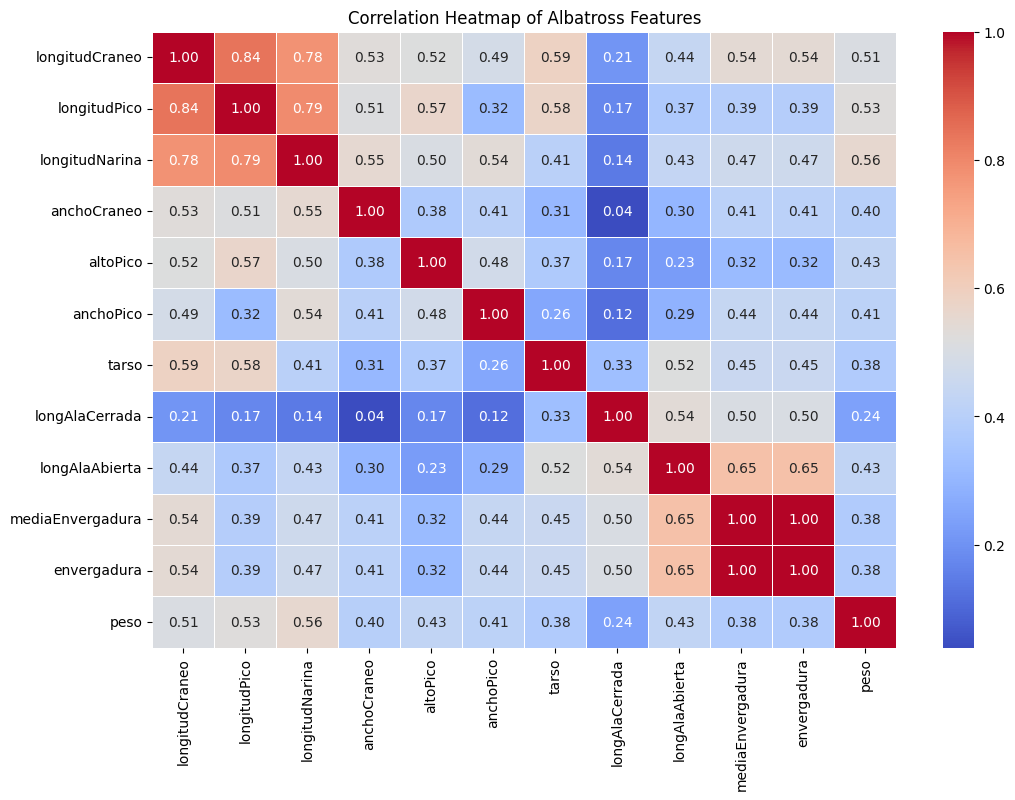

In [ ]:
# Select numerical features only
numeric_data = train.select_dtypes(include='number')

# Calculate correlation
correlation_matrix = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Albatross Features')
plt.show()

longAlaCerrada      0.173981
anchoPico           0.367129
longAlaAbierta      0.374416
mediaEnvergadura    0.414570
envergadura         0.414570
anchoCraneo         0.512906
tarso               0.528502
altoPico            0.578149
peso                0.604628
longitudNarina      0.629824
longitudCraneo      0.696123
longitudPico        0.729714
Name: sexo_encoded_temp, dtype: float64


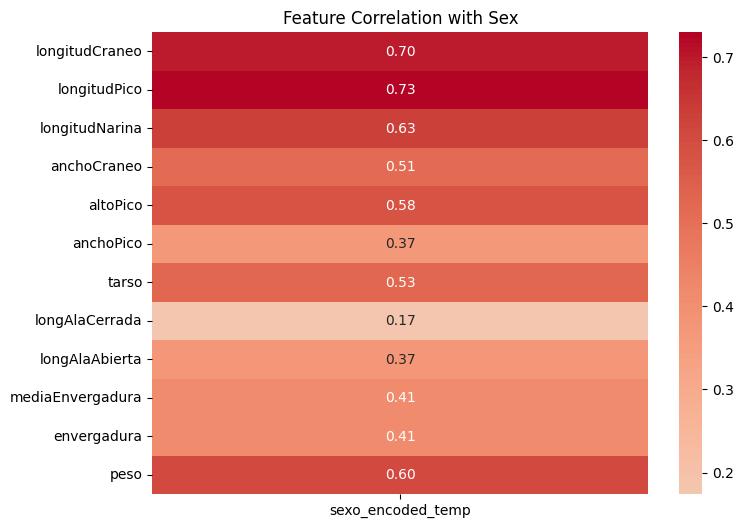

In [ ]:
target_encoded = train["sexo"].map({"H": 0, "M": 1})
numeric_data = train.select_dtypes(include="number").copy()
numeric_data["sexo_encoded_temp"] = target_encoded

correlation = numeric_data.corr()

print(
    correlation["sexo_encoded_temp"]
    .drop("sexo_encoded_temp")
    .sort_values()
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation[["sexo_encoded_temp"]].drop("sexo_encoded_temp"),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Feature Correlation with Sex")
plt.show()

In [ ]:
# Reload test data to recover its original IDs
test = pd.read_csv(
    "/content/drive/MyDrive/DSA/kaggle competition/test.csv"
)

test_ids = test["id"].copy()

# Remove unnecessary and redundant columns
train.drop(
    columns=["id", "envergadura", "sexo_encoded"],
    errors="ignore",
    inplace=True
)

test.drop(
    columns=["id", "envergadura"],
    errors="ignore",
    inplace=True
)

# Create the same features in both datasets
for df in [train, test]:
    df["beak_skull_ratio"] = (
        df["longitudPico"] / df["longitudCraneo"]
    )

    df["beak_height_ratio"] = (
        df["altoPico"] / df["longitudPico"]
    )

    df["beak_width_ratio"] = (
        df["anchoPico"] / df["longitudPico"]
    )

print("Feature engineering completed!")

Feature engineering completed!


In [ ]:
train.head()

,sexo,longitudCraneo,longitudPico,longitudNarina,anchoCraneo,altoPico,anchoPico,tarso,longAlaCerrada,longAlaAbierta,mediaEnvergadura,peso,beak_skull_ratio,beak_height_ratio,beak_width_ratio
0,H,174.18,106.85,80.19,52.43,30.20,23.26,88.74,51.0,95.7,104.2,2.38,0.613446,0.282639,0.217688
1,H,171.12,104.59,79.45,51.14,30.61,24.04,90.22,50.5,94.4,102.2,2.14,0.611209,0.292667,0.229850
2,H,174.69,106.83,82.14,49.09,30.60,26.47,91.42,52.7,96.6,105.2,2.50,0.611540,0.286436,0.247777
3,M,182.25,113.17,84.13,52.26,32.08,26.07,91.74,52.6,98.9,107.6,2.83,0.620960,0.283467,0.230361
4,H,173.70,105.19,80.37,49.20,34.00,27.12,87.77,50.8,94.5,103.7,2.73,0.605584,0.323225,0.257819


In [ ]:
print("Sex distribution:")
print(train["sexo"].value_counts())

print("\nSex distribution in percentage:")
print((train["sexo"].value_counts(normalize=True) * 100).round(2))

Sex distribution:
sexo
H    57
M    37
Name: count, dtype: int64

Sex distribution in percentage:
sexo
H    60.64
M    39.36
Name: proportion, dtype: float64


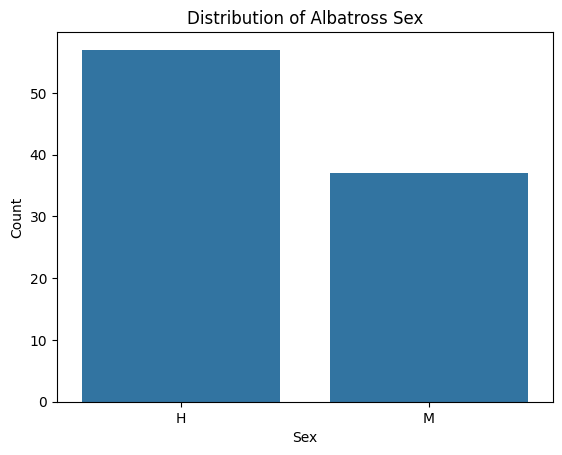

In [ ]:
sns.countplot(data=train, x='sexo')

plt.title('Distribution of Albatross Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Stratified 5-fold cross-validation is ready.")

Stratified 5-fold cross-validation is ready.


In [ ]:
from sklearn.model_selection import train_test_split

X = train.drop(
    columns=['sexo', 'sexo_encoded'],
    errors='ignore'
)

y = train['sexo']

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Training features: (75, 14)
Validation features: (19, 14)
Training target: (75,)
Validation target: (19,)

Training class distribution:
sexo
H    45
M    30
Name: count, dtype: int64

Validation class distribution:
sexo
H    12
M     7
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_val)

print("Accuracy:", accuracy_score(y_val, y_pred))
print("F1-score:", f1_score(y_val, y_pred, pos_label='M'))

print("\nClassification Report:")
print(classification_report(y_val, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred, labels=['H', 'M']))

Accuracy: 0.8947368421052632
F1-score: 0.8571428571428571

Classification Report:
              precision    recall  f1-score   support

           H       0.92      0.92      0.92        12
           M       0.86      0.86      0.86         7

    accuracy                           0.89        19
   macro avg       0.89      0.89      0.89        19
weighted avg       0.89      0.89      0.89        19


Confusion Matrix:
[[11  1]
 [ 1  6]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": model,

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", ExtraTreesClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ])
}

results = []

for name, clf in models.items():
    clf.fit(X_train, y_train)
    predictions = clf.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_val, predictions), 4),
        "F1-score (M)": round(
            f1_score(y_val, predictions, pos_label="M"), 4
        )
    })

import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.sort_values("F1-score (M)", ascending=False))


                 Model  Accuracy  F1-score (M)
0  Logistic Regression    0.8947        0.8571
2          Extra Trees    0.8947        0.8571
3                  SVM    0.8947        0.8571
1        Random Forest    0.8421        0.7692


In [ ]:

from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

f1_scorer = make_scorer(f1_score, pos_label="M")

cv_results = []

for name, clf in models.items():
    scores = cross_val_score(
        clf,
        X,
        y,
        cv=cv,
        scoring=f1_scorer
    )

    cv_results.append({
        "Model": name,
        "Mean F1-score": scores.mean(),
        "Std F1-score": scores.std(),
        "Fold scores": scores.round(3).tolist()
    })

cv_df = pd.DataFrame(cv_results)
cv_df = cv_df.sort_values("Mean F1-score", ascending=False)

print(cv_df.to_string(index=False))


              Model  Mean F1-score  Std F1-score                         Fold scores
                SVM       0.861754      0.126872       [1.0, 0.8, 0.842, 1.0, 0.667]
        Extra Trees       0.853968      0.140330     [1.0, 0.714, 0.889, 1.0, 0.667]
      Random Forest       0.838584      0.127067   [0.923, 0.714, 0.889, 1.0, 0.667]
Logistic Regression       0.827350      0.095849 [0.923, 0.769, 0.889, 0.889, 0.667]


In [ ]:
# Build the final SVM model
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

# Train on all labeled data
final_model.fit(X, y)

# Predict the sex of the test birds
test_predictions = final_model.predict(test[X.columns])

print("Predictions generated:", len(test_predictions))
print("Predicted classes:")
print(pd.Series(test_predictions).value_counts())


Predictions generated: 41
Predicted classes:
M    22
H    19
Name: count, dtype: int64


In [ ]:
print("Test dataset shape:", test.shape)
print("Predictions:", len(test_predictions))
print("Sample submission shape:", sample_submission.shape)

print("\nSample submission columns:")
print(sample_submission.columns.tolist())

print("\nSample submission:")
print(sample_submission)

Test dataset shape: (41, 14)
Predictions: 41
Sample submission shape: (3, 2)

Sample submission columns:
['id', 'sexo']

Sample submission:
     id sexo
0  id_1    M
1  id_2    H
2  id_3    M


In [ ]:
submission = pd.DataFrame({
    "id": test_ids,
    "sexo": test_predictions
})

print(submission.head())
print("Submission shape:", submission.shape)

submission.to_csv("/content/drive/MyDrive/DSA/kaggle competition/submissionfinal.csv", index=False)

         id sexo
0  A70_2018    M
1  5C9_2018    H
2  5E1_2018    M
3  C58_2018    M
4  5E2_2018    M
Submission shape: (41, 2)


In [ ]:
check = pd.read_csv("/content/drive/MyDrive/DSA/kaggle competition/submissionfinal.csv")

assert len(check) == 41, "Incorrect number of rows"
assert check["sexo"].notna().all(), "Missing predictions"
assert set(check["sexo"].unique()).issubset({"H", "M"}), "Invalid labels"

print("Submission is ready!")
print(check["sexo"].value_counts())

Submission is ready!
sexo
M    22
H    19
Name: count, dtype: int64


In [ ]:
# Reload original training data
raw_train = pd.read_csv(
    "/content/drive/MyDrive/DSA/kaggle competition/train.csv"
)

# Keep the original missing values
y_clean = raw_train["sexo"].copy()

X_clean = raw_train.drop(
    columns=["id", "sexo", "envergadura"],
    errors="ignore"
).copy()

# Add the same engineered features
X_clean["beak_skull_ratio"] = (
    X_clean["longitudPico"] / X_clean["longitudCraneo"]
)
X_clean["beak_height_ratio"] = (
    X_clean["altoPico"] / X_clean["longitudPico"]
)
X_clean["beak_width_ratio"] = (
    X_clean["anchoPico"] / X_clean["longitudPico"]
)

clean_svm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

scores = cross_val_score(
    clean_svm,
    X_clean,
    y_clean,
    cv=cv,
    scoring=make_scorer(f1_score, pos_label="M")
)

print("Fold F1-scores:", scores.round(3))
print("Mean F1-score:", round(scores.mean(), 4))
print("Std deviation:", round(scores.std(), 4))

Fold F1-scores: [1.    0.8   0.842 1.    0.667]
Mean F1-score: 0.8618
Std deviation: 0.1269
